# Wikipedia recommender system: report

*Information Retrieval project, Poznan University of Technology.*

The system recommends English Wikipedia articles similar to a collection of visited ones. **Input:** a
list of article titles or URLs. **Output:** a ranked list of corpus articles (title and link) with a score
in [0, 1], and an explanation of each score.

```text
Stage 1  crawler/        Vital articles lists ──► 8,800 articles ──► data/raw/articles_raw.parquet
Stage 2  preprocessing/  clean ► tokenize ► lemmatize + stem ──► data/processed/articles_processed.parquet
Stage 3  recommender/    TF-IDF + links + embeddings ► similarity ► interests ► top-k with scores
Stage 5  visualization/  corpus statistics and score breakdowns (this report)
```

Every chart below is computed from the data when the notebook runs; `reports/figures/` keeps a copy of
each. To try the recommender with your own articles, use `notebooks/02_recommender_demo.ipynb` or
`python -m wiki_recommender.recommender "Dog" "Cat"`.

**Contents**
1. Crawling and scraping
2. Preprocessing: stemming and lemmatization
3. Scoring: how articles are recommended
4. Statistics of the database
5. Examples of recommendations, with explanations
6. Evaluation and limitations

In [1]:
import os
from pathlib import Path

# Data paths are relative to the repository root, so run from there wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from wiki_recommender.recommender import Recommender
from wiki_recommender.visualization import breakdown, corpus, evaluation
from wiki_recommender.visualization.style import apply_style, save

warnings.filterwarnings("ignore")
apply_style()
pd.set_option("display.precision", 3)

recommender = Recommender.load()
model = recommender.model
frame = corpus.load_corpus_frame()
raw_stats = corpus.load_stats(corpus.RAW_STATS_PATH)
stats = corpus.load_stats(corpus.PROCESSED_STATS_PATH)
representation_eval = evaluation.load_eval(evaluation.REPRESENTATION_EVAL_PATH)
recommender_eval = evaluation.load_eval(evaluation.RECOMMENDER_EVAL_PATH)


def show(figure, name):
    """Display a chart and keep a copy in reports/figures."""
    figure = getattr(figure, "figure", figure)
    save(figure, name)
    plt.show()


def as_table(result) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "rank": r.rank,
                "title": r.title,
                "score": r.score,
                "text": r.signal_contributions["text"],
                "links": r.signal_contributions["links"],
                "embedding": r.signal_contributions["embedding"],
                "compared with": ", ".join(r.interest),
                "shared terms": ", ".join(r.shared_terms[:4]),
            }
            for r in result.recommendations
        ]
    ).set_index("rank")

## 1. Crawling and scraping

**Source.** Articles come from English Wikipedia's
[Vital articles](https://en.wikipedia.org/wiki/Wikipedia:Vital_articles) lists, levels 4 and 5, which sort
about 50,000 important articles into 11 topics and thousands of subsections. Using them instead of a
random walk over links gives a corpus that is broad, made of substantial articles, and labelled: each
article carries its topic and subsection, which the evaluation later uses as ground truth.

**Selection.** Each topic gets the same quota of 800 articles:
1. articles of levels 1-3 (such as *World War II* or *Dog*) are always taken;
2. the rest is a 60/40 mix of level 4 articles and narrower level 5 ones, which add niche subjects;
3. within a level, subsections take turns (round-robin), most-read first by 60 days of page views, so
   popular subjects are favoured without crowding out quiet ones.

**Filtering.** Disambiguation pages, redirects to an article already collected, link collections
(`List of ...`, `Outline of ...`), pages outside the main namespace and pages under 100 words are rejected.

**Scraping.** Each page is fetched with the MediaWiki `action=parse` API and its HTML is reduced to
running prose: infoboxes, tables, navigation templates, figures, formulas, pronunciation guides,
citation markers and trailing sections (*See also*, *References*, *External links*) are removed. The
title, URL, lead section, section headings, categories and outgoing links are stored separately.

**Politeness.** A descriptive `User-Agent`, at least 0.25 s between requests, `maxlag=5` (the crawler
yields when Wikipedia's servers are busy) and exponential backoff on errors or `Retry-After`. An
interrupted crawl resumes from a checkpoint.

In [2]:
words = raw_stats["words"]
pd.DataFrame(
    {
        "articles": [raw_stats["articles"]],
        "candidates in the lists": [raw_stats["candidates_discovered"]],
        "topics": [len(raw_stats["per_topic"])],
        "subsections": [raw_stats["distinct_seed_sections"]],
        "categories": [raw_stats["distinct_categories"]],
        "words in total": [words["total"]],
        "median words per article": [words["median"]],
    }
).T.rename(columns={0: "value"}).style.format("{:,}")

,value
articles,"8,800"
candidates in the lists,"49,721"
topics,11
subsections,"3,241"
categories,"58,638"
words in total,"50,947,183"
median words per article,"4,912"


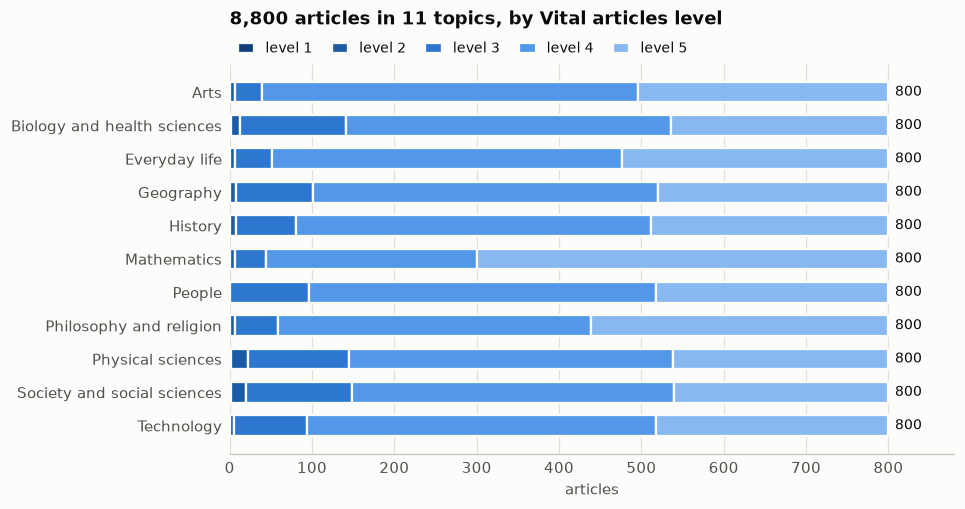

In [3]:
show(corpus.plot_topic_composition(frame), "topic_composition")

Every topic holds exactly 800 articles. The share of level 5 articles differs between topics because
the lists differ: Mathematics has few level 1-4 articles, so most of its quota comes from level 5.

## 2. Preprocessing: stemming and lemmatization

**Cleaning.** The crawler already removes most markup. This stage removes what is left: URLs, stray
HTML tags, `[[ ]]` and `{{ }}` brackets, unfilled template parameters and repeated whitespace.
Categories that describe Wikipedia's own maintenance (*Articles with short description*, *Living
people*) are dropped, because they say nothing about the subject.

**Tokens, lemmas and stems.** Every article is tokenized once with spaCy (`en_core_web_sm`). Each word
that passes one shared filter yields both a **lemma** (spaCy, part-of-speech aware) and a **stem**
(NLTK Snowball), so the two token lists stay aligned word for word:

* case and accents are folded (*Müller* = *Muller*);
* stopwords, punctuation, numbers, ordinals (*19th*) and year ranges are removed; all-caps acronyms
  (*US*, *WHO*) are kept;
* tokens must be Latin-script, 2 to 40 characters long and contain a letter (`covid-19` survives).

**Repairing lemmas.** spaCy guesses the lemma of an unknown word by stripping a plural ending, which
gives `cryptocurrencie`, or turns *series* into `serie`. After the whole corpus is read, such a guess is
kept only if the corpus itself contains the singular at least a tenth as often as the plural:
*cryptocurrencies* becomes `cryptocurrency`, while *series* and *species* stay whole. 9,840 lemmas were
repaired this way.

**Stored form.** `articles_processed.parquet` keeps, for each article, the lemmas and the stems of its
text, its *definition* (the first full lead paragraph, which says what the subject is), the length of
its lead, and its lemmatized categories.

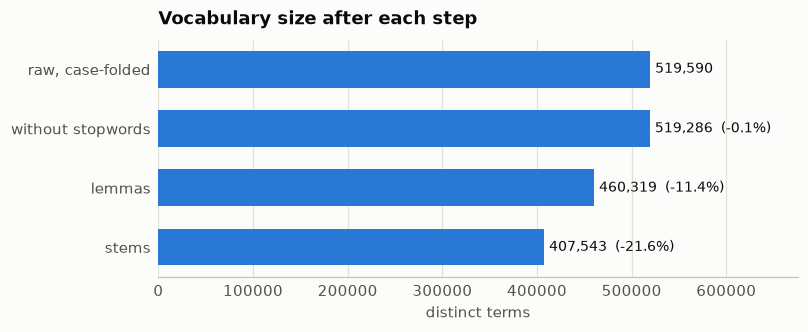

In [4]:
show(corpus.plot_vocabulary(stats), "vocabulary")

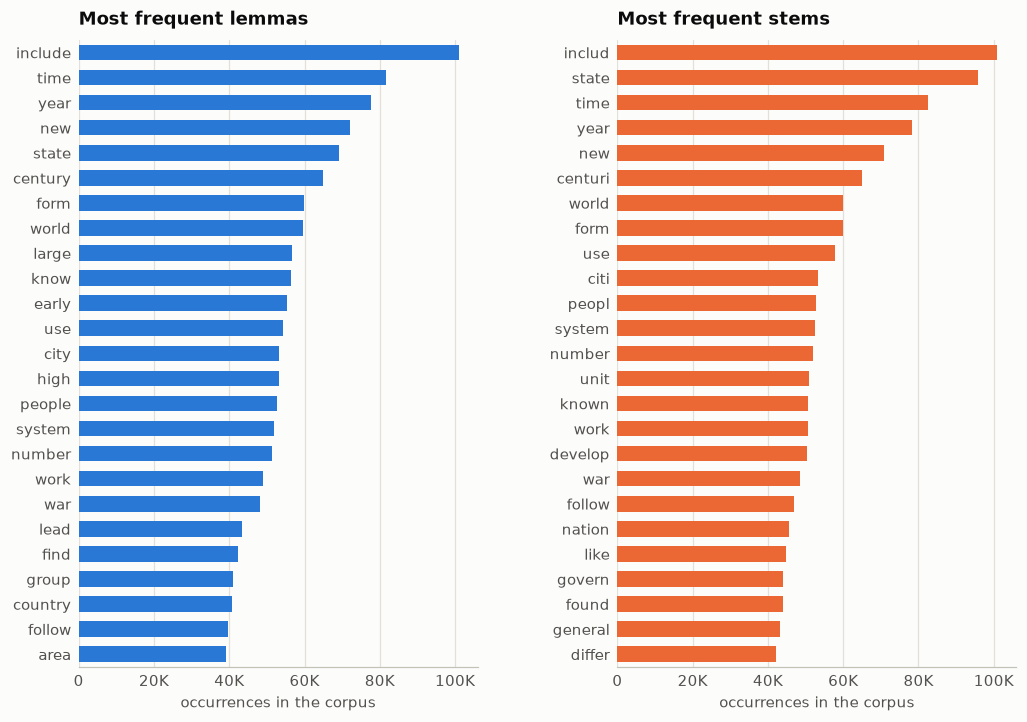

In [5]:
show(corpus.plot_top_words(stats, 25), "top_words")

**Lemmas or stems?** Stemming shrinks the vocabulary more, but it also merges unrelated words: *universe*
and *university* share the stem `univers`, and *united* and *unit* share `unit`, which is why `unit`
ranks far higher among stems than `united` among lemmas. Lemmas are real words, which keeps the term
charts and score explanations readable (`university`, not `univers`).

The choice was also measured. Each representation is judged by how often an article's 10 nearest
neighbours are related to it by signals that do not come from its text: the same Vital articles
subsection, and a shared category from a held-out half of the categories. Settings were chosen on one
half of the articles and measured on the other half (4,407 articles).

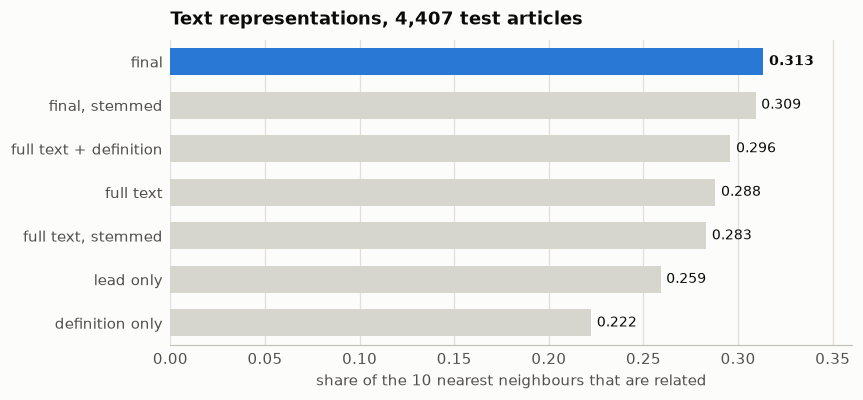

In [6]:
show(evaluation.plot_representation_eval(representation_eval), "representation_eval")

In [7]:
comparisons = pd.DataFrame(representation_eval["comparisons_on_test"]).T
comparisons.columns = ["difference", "95% low", "95% high"]
comparisons

,difference,95% low,95% high
final vs full text,0.025,0.022,0.029
final vs definition only,0.091,0.086,0.096
final vs lead only,0.054,0.050,0.059
full text vs definition only,0.066,0.060,0.071
"final vs final, stemmed",0.004,0.003,0.006
"full text vs full text, stemmed",0.005,0.003,0.007


Lemmas beat stems by a small margin, but consistently (the paired bootstrap interval excludes zero), so
**lemmas are the canonical representation**. Adding the definition again (weight 0.5) and the category
tokens (weight 0.25) improves on the full text alone by +0.025. The final text vector of an article is

$$\mathbf{t} = \operatorname{norm}\big(\operatorname{norm}(\text{tfidf}(\text{article}) + 0.5\,\text{tfidf}(\text{definition}))
\;\Vert\; 0.25\,\text{tfidf}(\text{categories})\big)$$

with sublinear TF ($1 + \log tf$), IDF fitted on the corpus, terms in at least two articles, and
$\Vert$ the concatenation of the word and category features.

## 3. Scoring: how articles are recommended

### 3.1 Similarity of two articles

Three signals compare a visited article $v$ with a candidate $c$. Each is a cosine similarity in [0, 1]:

| Signal | Representation | Weight |
| :--- | :--- | ---: |
| Text | the TF-IDF vector $\mathbf{t}$ of section 2 | 0.55 |
| Links | TF-IDF over the pages an article links to, plus its own title, so shared links and direct links both count | 0.05 |
| Embedding | `BAAI/bge-small-en-v1.5` sentence embedding of the title and the first 150 words | 0.40 |

$$s(v, c) = 0.55\,\cos_{\text{text}}(v, c) + 0.05\,\cos_{\text{links}}(v, c) + 0.40\,\max\big(0, \cos_{\text{emb}}(v, c)\big)$$

The weights sum to 1, so $s(v, c) \in [0, 1]$. Text and embeddings complement each other: TF-IDF
matches exact terms and names, the embedding matches meaning when the words differ.

### 3.2 From a history to one score

A history $V = \{v_1, \dots, v_m\}$ is first split into **interests**: visited articles are clustered
with average linkage on $1 - s(v_i, v_j)$, and two stay together while their mean similarity is at least
$t = 0.3$. For a candidate $c \notin V$ and an interest $I$:

$$\text{score}_I(c) = \frac{1}{|I|} \sum_{v \in I} s(v, c), \qquad \text{score}(c) = \max_I\, \text{score}_I(c)$$

The top-$k$ list is shared between interests in proportion to their size (each interest contributes its
best candidates), visited articles are never recommended, and the list is sorted by score. With a single
interest this is the plain mean, which ranks exactly like the centroid of the visited articles.

Why not just the mean? For a history about two unrelated subjects, the mean favours articles that sit
between both and match neither well. Section 6 measures this.

### 3.3 Explaining a score

Because the score is a mean of weighted cosines, it splits exactly into parts. With $\mathbf{u}$ the
mean text vector of the interest:

$$\text{score}(c) = \underbrace{\sum_{\text{terms } w} 0.55\, u_w\, c_w}_{\text{shared terms}}
+ 0.05\,\overline{\cos}_{\text{links}} + 0.40\,\overline{\cos}_{\text{emb}}
= \frac{1}{|I|}\sum_{v \in I} s(v, c)$$

The first form gives the **waterfall** charts (which shared words and which signals add up to the
score), the second the **per-visited-article** charts (how much each visited article contributes).

## 4. Statistics of the database

### 4.1 Article length

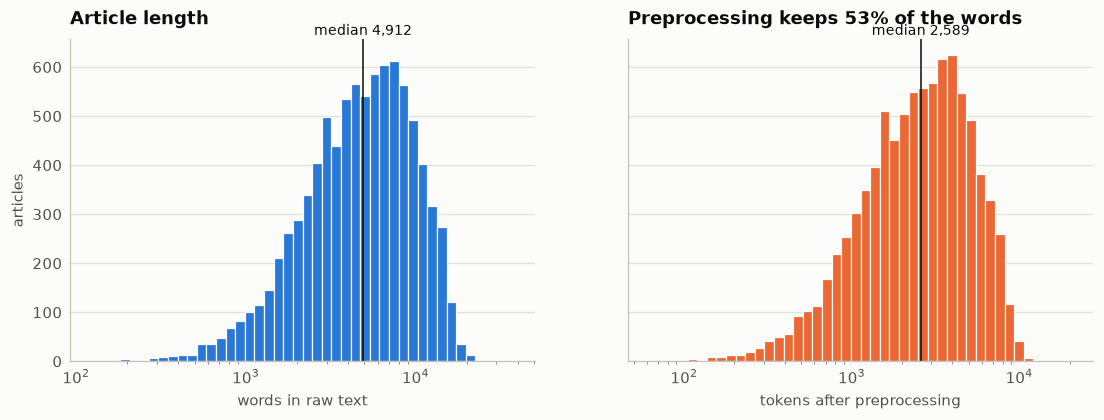

In [8]:
show(corpus.plot_length_histograms(frame), "length_histograms")

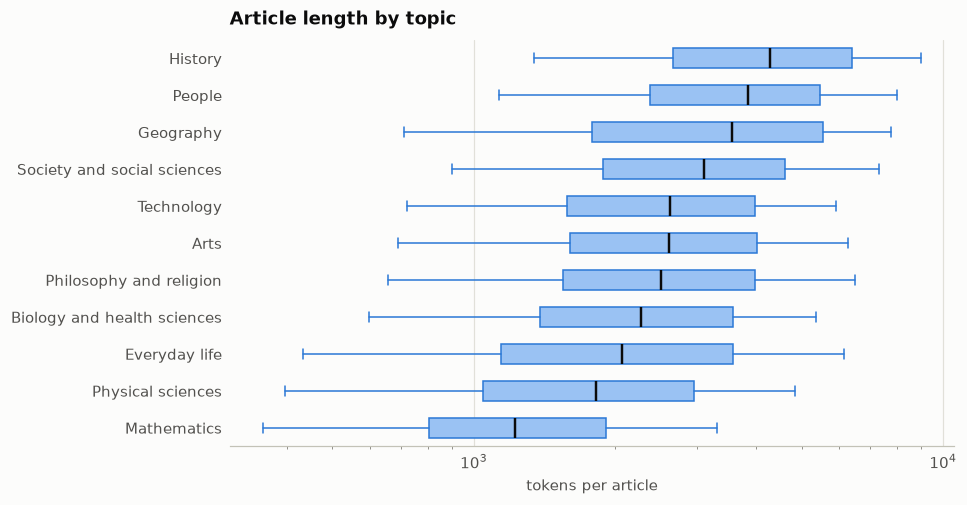

In [9]:
show(corpus.plot_length_by_topic(frame), "length_by_topic")

In [10]:
frame[["word_count", "token_count", "lead_token_count", "categories", "outlinks", "sections"]].describe(
    percentiles=[0.1, 0.5, 0.9]
).T[["mean", "min", "10%", "50%", "90%", "max"]].round(0)

,mean,min,10%,50%,90%,max
word_count,5789.0,123.0,1642.0,4912.0,11251.0,38017.0
token_count,3056.0,62.0,837.0,2589.0,6006.0,20654.0
lead_token_count,157.0,8.0,57.0,146.0,274.0,620.0
categories,11.0,1.0,2.0,6.0,24.0,137.0
outlinks,228.0,5.0,67.0,188.0,436.0,2112.0
sections,24.0,0.0,8.0,22.0,44.0,143.0


Lengths are roughly log-normal: the median article has about 4,900 words, and the longest about 38,000.
Preprocessing keeps about half of the words; most of the rest are stopwords. Biographies and history
articles are the longest, mathematics articles the shortest.

### 4.2 Most important terms

The most frequent lemmas (section 2) are general words such as *include*, *time* and *year*. TF-IDF
weights tell more: below, the highest mean weight over all articles (left), and for each topic the words
that stand out most against the rest of the corpus.

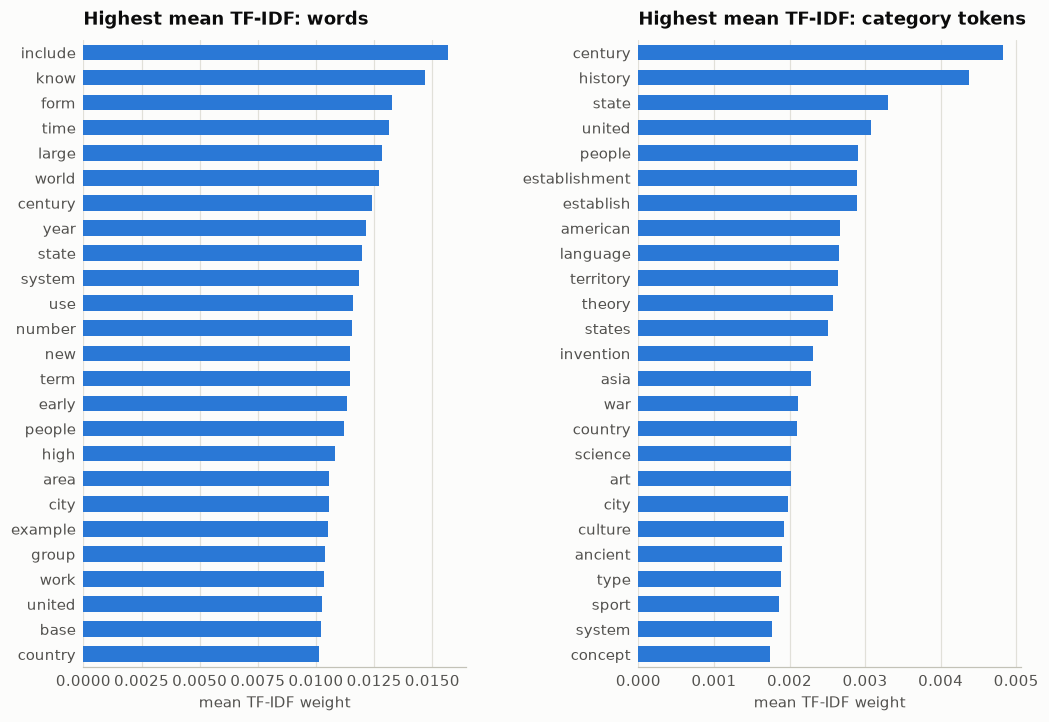

In [11]:
show(corpus.plot_top_tfidf(model, 25), "top_tfidf")

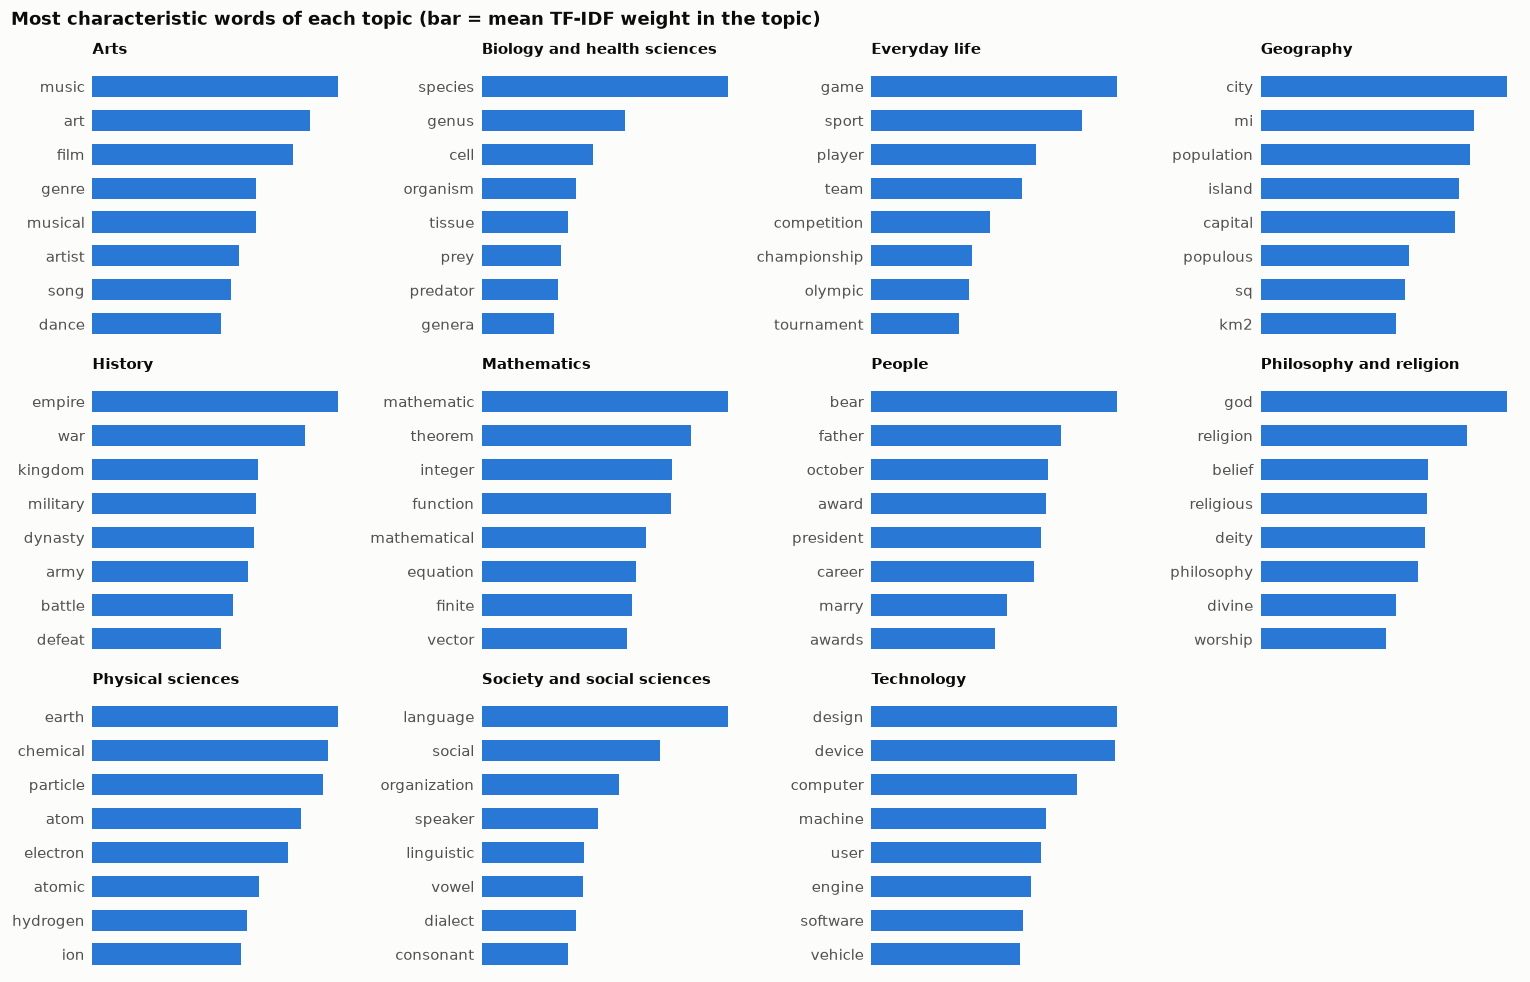

In [12]:
show(corpus.plot_topic_terms(model, 8), "topic_terms")

Each topic is recognisable from its words alone. Two artefacts of lemmatization show here: in *People*,
`bear` is the lemma of *born*, and in *Geography* `mi` and `sq` come from *sq mi*, the area unit.

### 4.3 Similarities between documents

Similarities among 2,000 random articles (about 2 million pairs), for each signal and for the combined
score $s$:

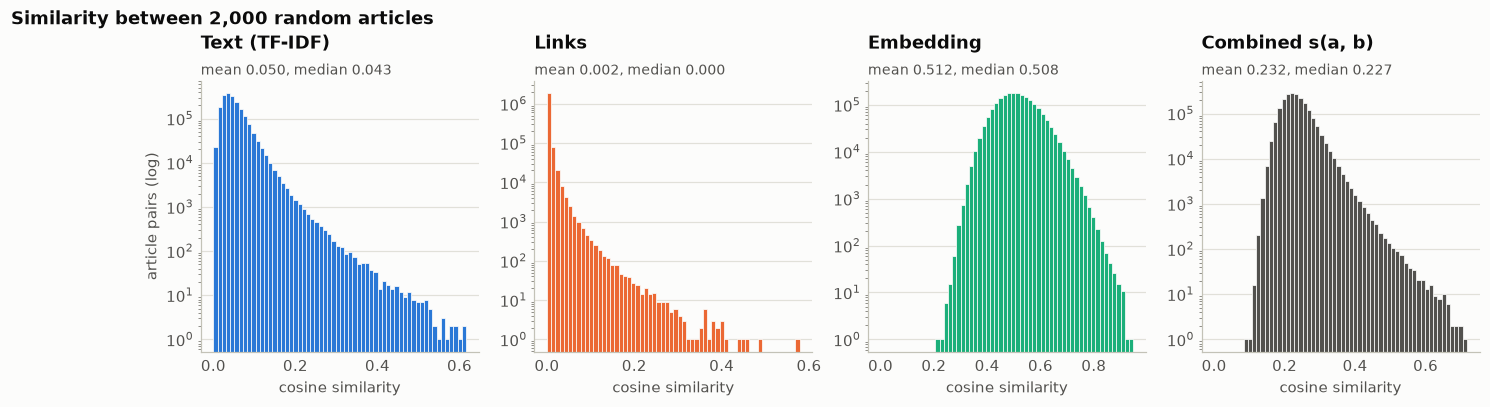

In [13]:
sample = corpus.similarity_sample(model, size=2000)
show(corpus.plot_similarity_distributions(sample), "similarity_distributions")

The signals behave very differently. Text and link vectors are sparse, so most pairs of unrelated
articles share almost nothing (link similarity is exactly 0 for most pairs). Embeddings are never far
apart: even unrelated articles have a cosine of about 0.5. The combined score therefore has a floor of
about 0.2 for unrelated articles, and good recommendations score roughly 0.4-0.6.

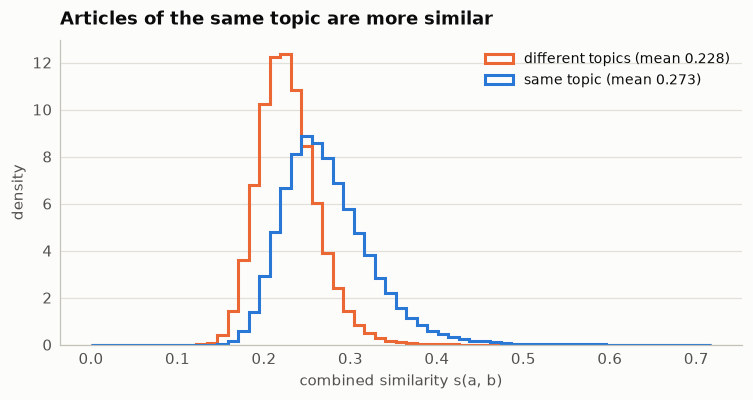

In [14]:
show(corpus.plot_same_vs_other_topic(sample), "same_vs_other_topic")

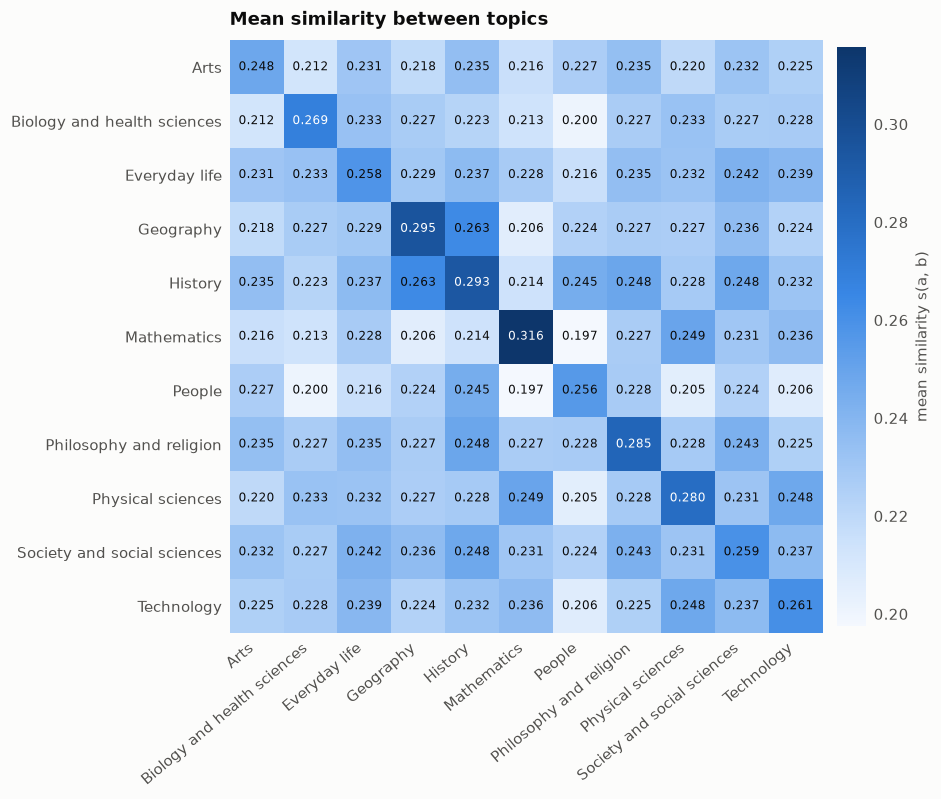

In [15]:
topics = corpus.topic_similarity_matrix(sample)
show(corpus.plot_topic_heatmap(topics), "topic_similarity")

Articles are most similar within their own topic (the diagonal). Mathematics is the most self-contained
topic. The strongest pair of different topics is Geography and History, followed by Mathematics and
Physical sciences: countries and empires, and the mathematics of physics.

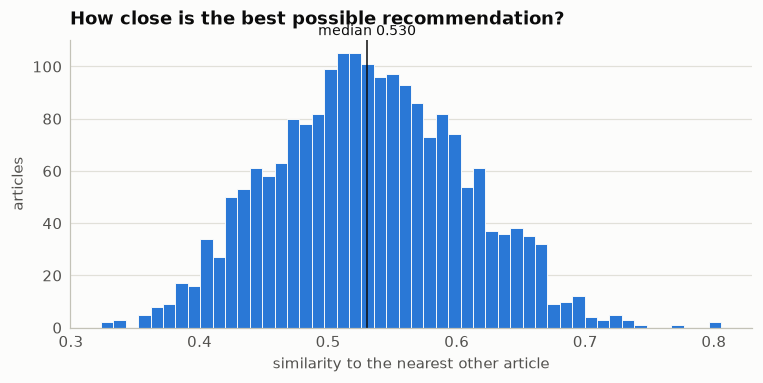

In [16]:
show(corpus.plot_nearest_neighbour(model, sample), "nearest_neighbour")

For almost every article the corpus holds a clearly related one, scoring well above the 0.2 floor of
unrelated pairs: the corpus is dense enough to recommend from.

### 4.4 A map of the corpus

A 2D t-SNE map of the embeddings of 3,000 random articles. Eleven topics are too many to tell apart by
color in one picture, so each panel highlights one topic over the whole map.

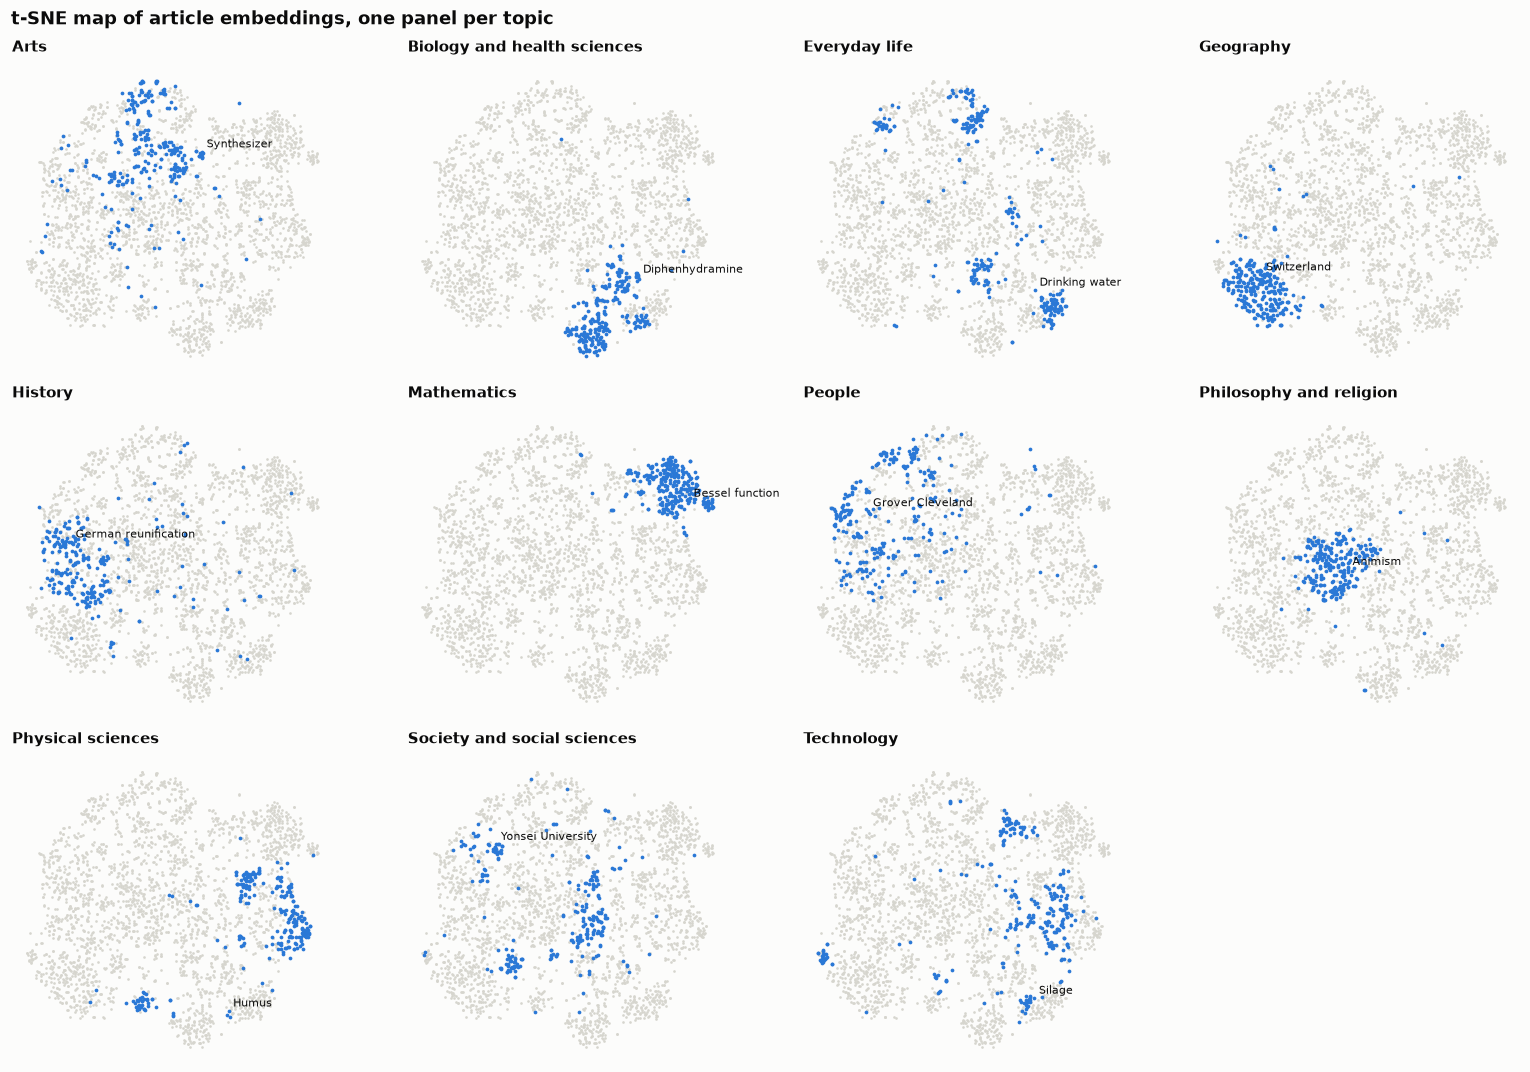

In [17]:
points = corpus.embedding_map(model, size=3000)
show(corpus.plot_embedding_map(points), "embedding_map")

Biology, Mathematics, Geography and Philosophy and religion form compact regions. People, History,
Society and Technology are spread out, because they touch every other subject: a biography of a
physicist sits next to physics, not next to other biographies.

## 5. Examples of recommendations, with explanations

### 5.1 One interest: popular music

Three visited articles about music, one given as a URL.

Visited: Jazz; Blues; Rock and roll

  #   Score  Title                       Shared terms
  1   0.569  Rock music                  genre, blue, jazz, music
  2   0.567  Rhythm and blues            rhythm, jazz, blue, music
  3   0.531  Music of the United States  category: music, jazz, music, ragtime
  4   0.520  Funk                        jazz, category: music, genre, music
  5   0.501  Soul music                  music, rhythm, african, genre
  6   0.480  Bluegrass music             genre, jazz, blue, music
  7   0.477  Bebop                       chord, jazz, improvisation, category: jazz
  8   0.469  Country music               category: music, music, genre, guitar
  9   0.459  Heavy metal music           category: music, rock, genre, blue
 10   0.448  Music genre                 genre, music, musical, category: music


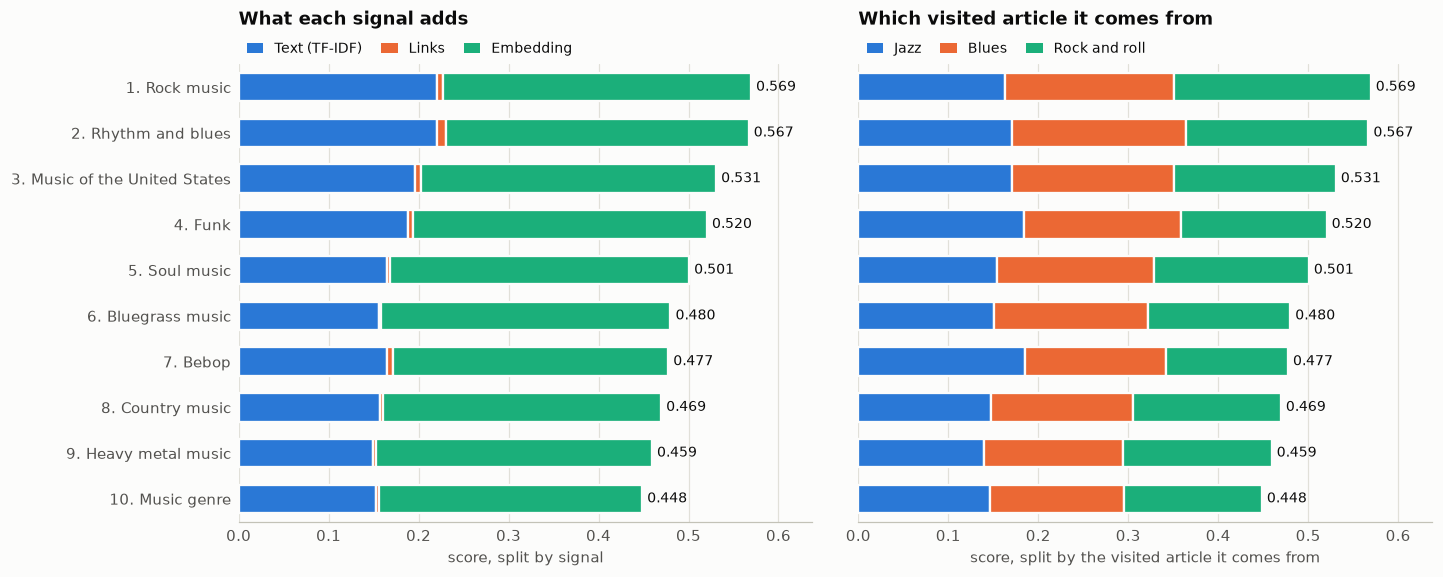

In [18]:
music = recommender.recommend(["Jazz", "Blues", "https://en.wikipedia.org/wiki/Rock_and_roll"], top_k=10)
print(music)
show(breakdown.explain_result(music), "example_music_result")

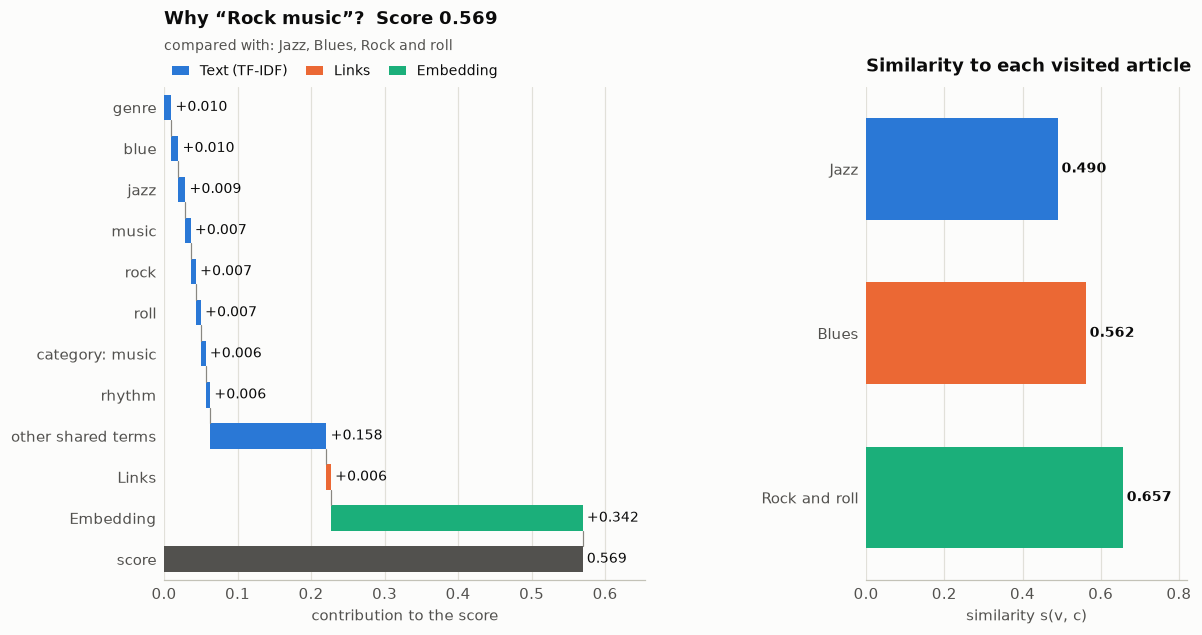

In [19]:
show(breakdown.explain(music, rank=1), "example_music_top")

All three visited articles form one interest, so every score is their mean similarity, and each
contributes about a third (right chart). The recommendations are the neighbouring genres. The waterfall
shows which shared words matter: `genre`, `blue` (the lemma of *blues*), `jazz`, `music`, `rock` and
`roll`. Most of the text part is spread over many smaller shared terms, and the embedding adds the
largest share.

### 5.2 Two interests: Ancient Rome and geometry

Visited: Ancient Rome; Julius Caesar; Pythagorean theorem; Euclid
Interests: Ancient Rome, Julius Caesar | Pythagorean theorem, Euclid

  #   Score  Title                           Shared terms
  1   0.589  Roman Republic                  roman, bc, rome, civilisation
  2   0.554  Mark Antony                     bc, roman, republic, antony
  3   0.549  Roman Empire                    roman, empire, bc, octavian
  4   0.539  Euclidean geometry              euclid, euclidean, geometry, theorem
  5   0.537  Augustus                        bc, roman, gaius, octavian
  6   0.531  Assassination of Julius Caesar  caesar, pompey, bc, roman
  7   0.489  Geometry                        geometry, euclidean, geometer, mathematic
  8   0.471  Euclidean space                 euclidean, geometry, euclid, mathematic
  9   0.470  Parallel postulate              geometry, euclid, euclidean, postulate
 10   0.452  Law of cosines                  triangle, cosine, theorem, pythagorean


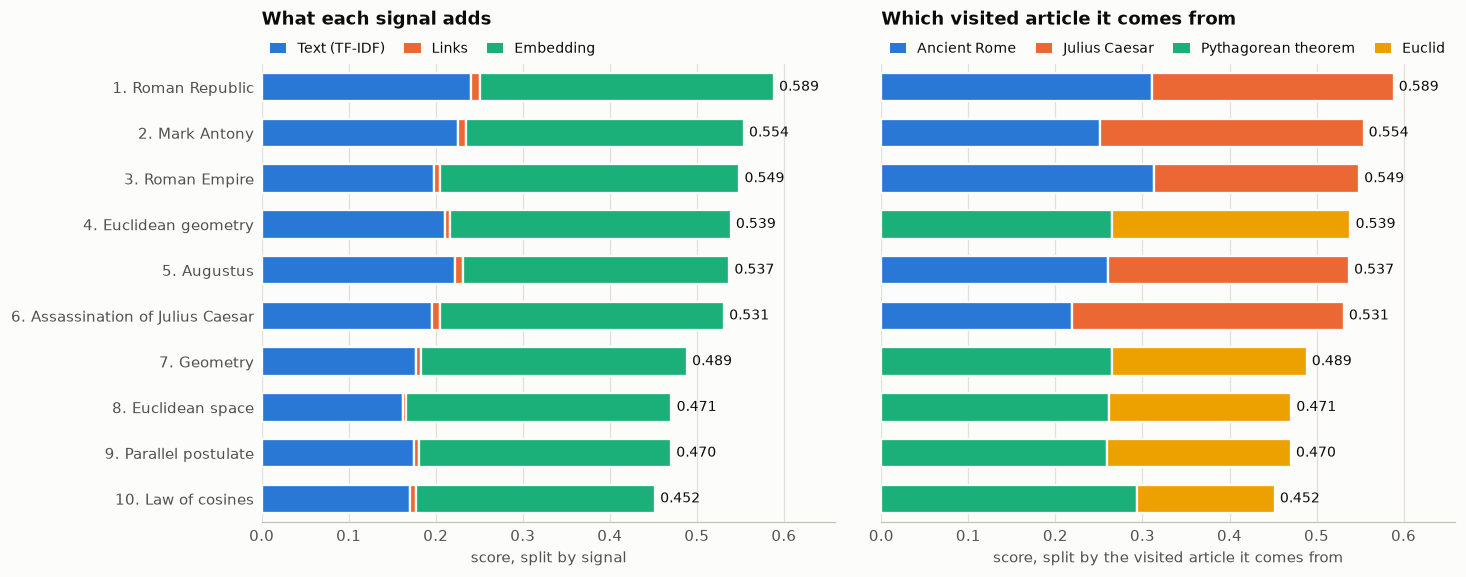

In [20]:
history = ["Ancient Rome", "Julius Caesar", "Pythagorean theorem", "Euclid"]
mixed = recommender.recommend(history, top_k=10)
print(mixed)
show(breakdown.explain_result(mixed), "example_mixed_result")

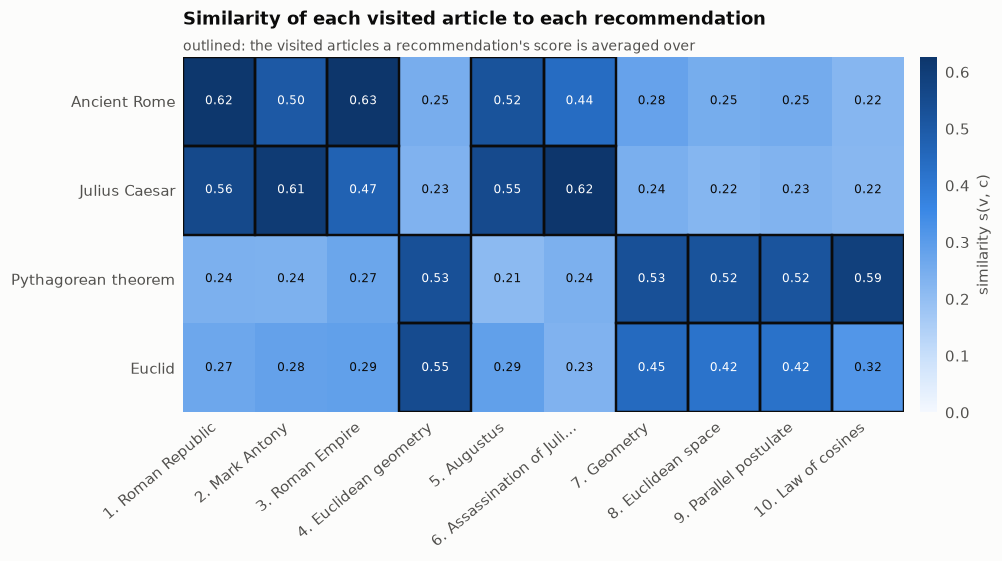

In [21]:
show(breakdown.plot_visited_heatmap(mixed), "example_mixed_heatmap")

The history is split into two interests, and both get recommendations. In the heatmap the outlined cells
are the visited articles each score is averaged over: Roman articles are scored only against *Ancient
Rome* and *Julius Caesar*, geometry articles only against *Pythagorean theorem* and *Euclid*. Compare
the plain mean over all four articles, which mixes both subjects into one profile:

In [22]:
mean = recommender.recommend(history, top_k=10, aggregation="power")
pd.DataFrame(
    {
        "interests (used)": [f"{r.title} ({r.score:.3f})" for r in mixed.recommendations],
        "plain mean": [f"{r.title} ({r.score:.3f})" for r in mean.recommendations],
    },
    index=range(1, 11),
)

,interests (used),plain mean
1,Roman Republic (0.589),Roman Republic (0.421)
2,Mark Antony (0.554),Roman Empire (0.414)
3,Roman Empire (0.549),Mark Antony (0.407)
4,Euclidean geometry (0.539),History of mathematics (0.395)
5,Augustus (0.537),Cicero (0.394)
6,Assassination of Julius Caesar (0.531),Augustus (0.394)
7,Geometry (0.489),Euclidean geometry (0.390)
8,Euclidean space (0.471),Assassination of Julius Caesar (0.384)
9,Parallel postulate (0.470),Roman emperor (0.383)
10,Law of cosines (0.452),Geometry (0.375)


The plain mean keeps only two geometry articles in its top 10 and brings in articles that sit between the
two subjects, such as *History of mathematics* and *Cicero*. Its scores are also lower, since every
candidate is compared with two visited articles from the other subject.

### 5.3 A niche subject: backgammon

A single visited article. The waterfall shows that the match goes beyond the word *game*: *dice*,
*board* and the name *backgammon* itself are shared.

Visited: Backgammon

  #   Score  Title             Shared terms
  1   0.498  Board game        dice, game, backgammon, board
  2   0.481  Go (game)         game, player, board, backgammon
  3   0.463  Checkers          game, checker, board, player
  4   0.452  Monopoly (game)   dice, player, game, board
  5   0.450  Dice              dice, backgammon, game, board
  6   0.436  Mahjong           player, game, dice, category: board
  7   0.432  History of games  game, backgammon, dice, category: game
  8   0.427  Pachisi           board, backgammon, player, category: board


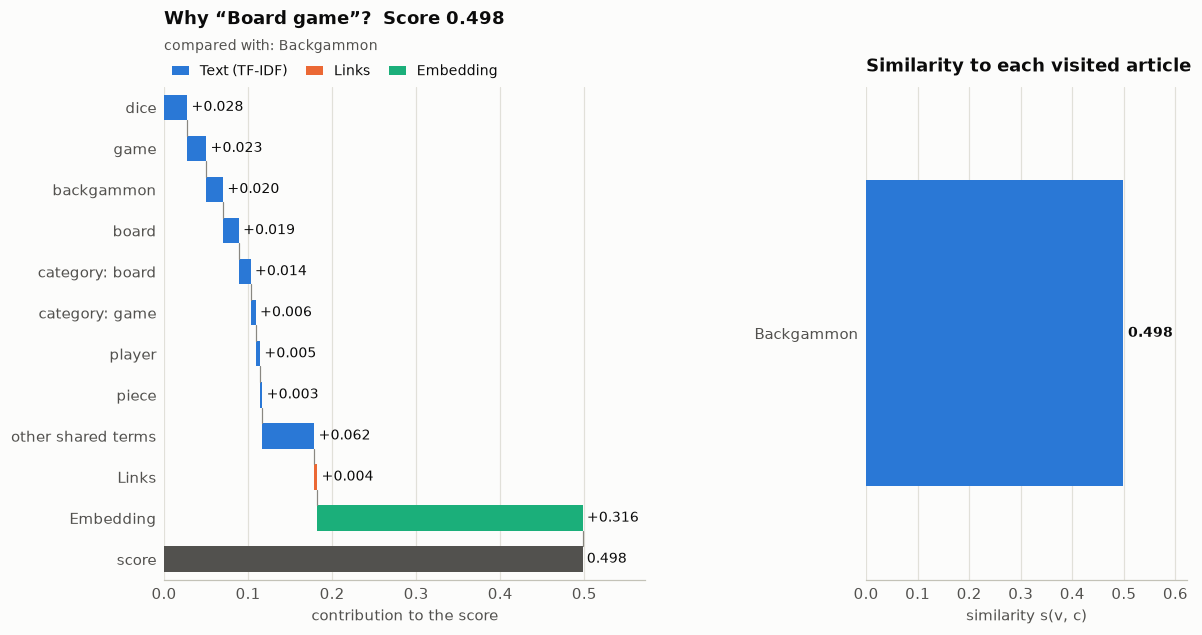

In [23]:
niche = recommender.recommend(["Backgammon"], top_k=8)
print(niche)
show(breakdown.explain(niche, rank=1), "example_niche_top")

### 5.4 An article outside the corpus

*Information retrieval* is not among the 8,800 articles. It is fetched from Wikipedia, extracted and
preprocessed exactly like the corpus (Stages 1 and 2), vectorized with the fitted model, and then used
like any visited article. Without internet access it is reported as unresolved instead.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Visited: Information retrieval (fetched); Search engine

  #   Score  Title           Shared terms
  1   0.491  Google Search   query, search, google, pagerank
  2   0.434  World Wide Web  web, hyperlink, www, query
  3   0.425  Web browser     web, browser, user, query
  4   0.424  Microsoft Bing  search, bing, query, web
  5   0.415  HTTP            web, hyperlink, query, user
  6   0.413  Database        database, query, retrieval, user
  7   0.406  Website         web, page, browser, user
  8   0.398  Web design      web, user, search, query


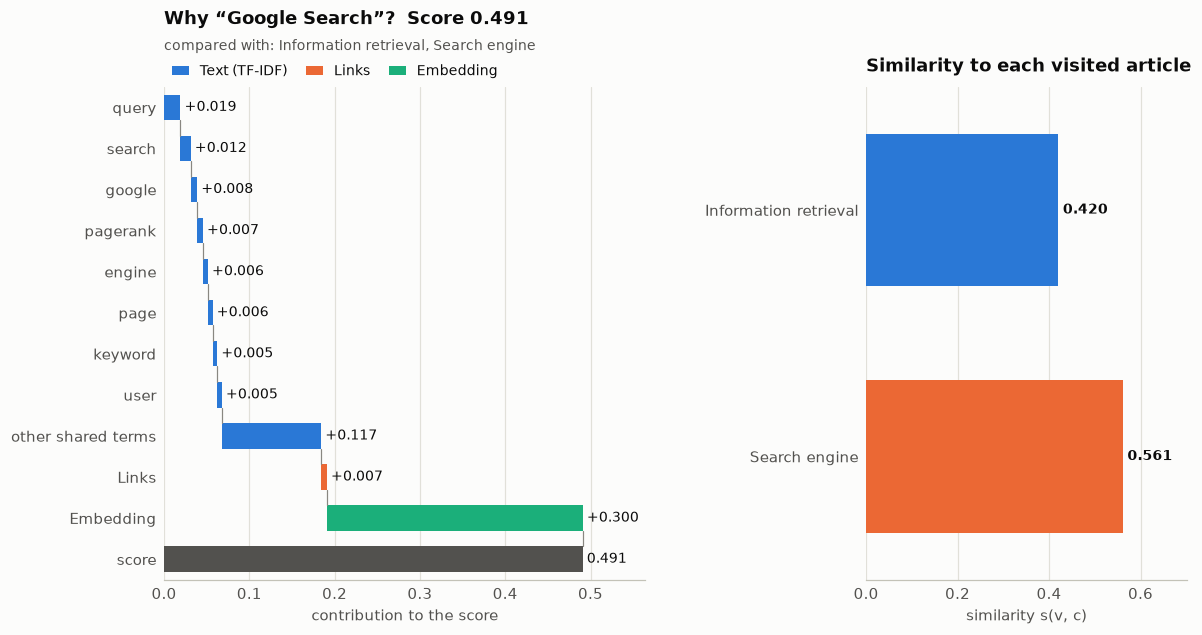

In [24]:
unseen = recommender.recommend(["Information retrieval", "Search engine"], top_k=8)
print(unseen)
if unseen.recommendations:
    show(breakdown.explain(unseen, rank=1), "example_unseen_top")

### 5.5 Inputs that cannot be used

Misspelled titles, disambiguation pages and URLs that are not Wikipedia articles are reported with the
reason and close titles; the remaining inputs are still used.

In [25]:
print(recommender.recommend(["Mercury", "Elektron", "https://example.com/page", "Dog"], top_k=5))

! Skipped 'Mercury': this is a disambiguation page; pick one of the meanings it lists. Did you mean: Mercury (planet), Mercury (element), Perjury?
! Skipped 'Elektron': this is a disambiguation page; pick one of the meanings it lists. Did you mean: Electron, Skeleton, Election?
! Skipped 'https://example.com/page': not an English Wikipedia article URL.
Visited: Dog

  #   Score  Title          Shared terms
  1   0.566  Wolf           canis, wolf, lupus, dog
  2   0.462  Cat            domesticate, category: animal, category: mammal, cat
  3   0.455  Horse          domesticate, breed, domesticated, domestication
  4   0.452  Coyote         canis, wolf, canid, gray
  5   0.446  Domestication  domestication, domesticate, dog, domesticated


## 6. Evaluation and limitations

The signals, their weights and the aggregation were chosen with the same offline protocol as the text
representation (section 2): an article's recommendations count as related if they share its Vital
articles subsection or a held-out category. Settings were tuned on half of the articles and are reported
on the other half.

### 6.1 Signals

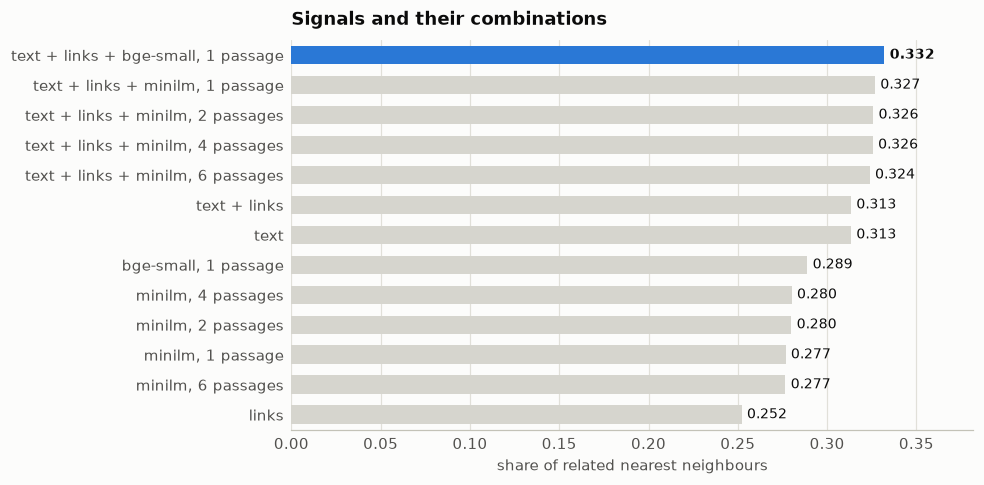

In [26]:
show(evaluation.plot_signal_eval(recommender_eval), "signal_eval")

In [27]:
signals = pd.DataFrame(recommender_eval["single_article_comparisons_on_test"]).T
signals.columns = ["difference", "95% low", "95% high"]
signals

,difference,95% low,95% high
"text + links + bge-small, 1 passage vs text",0.016,0.013,0.018
"text + links + bge-small, 1 passage vs text + links",0.016,0.013,0.018
"text + links + bge-small, 1 passage vs bge-small, 1 passage",0.039,0.036,0.043


Text and embeddings together beat text alone by +0.016 and the embedding alone by +0.039. Links add
almost nothing on top, as the text already contains the link anchors, so they keep a small weight.
bge-small beat MiniLM-L6, and embedding more than the first passage did not help once combined with text.

### 6.2 Aggregating a history

Simulated histories: one interest (3 or 5 articles of one subsection) or two interests (3 + 2 articles
from subsections of different topics). *Coverage* is the share of interests that get at least one
recommendation.

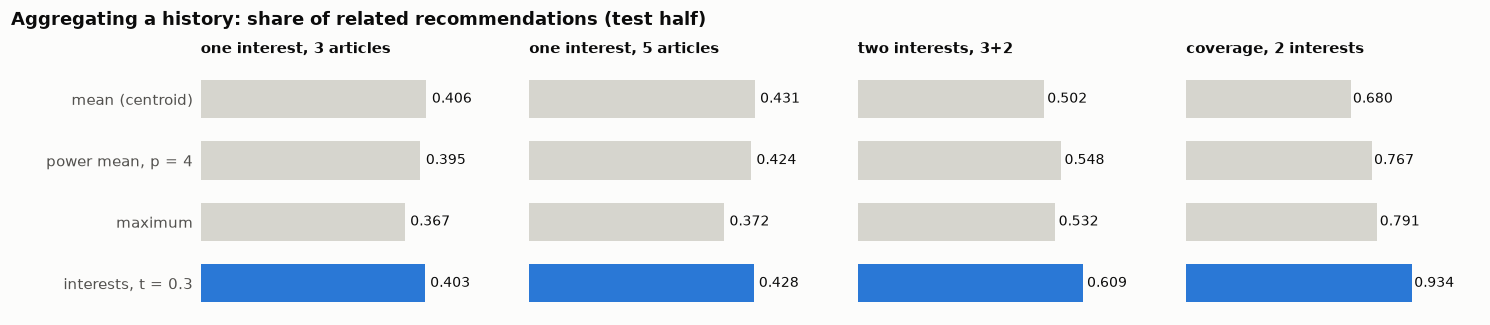

In [28]:
show(evaluation.plot_aggregation_eval(recommender_eval), "aggregation_eval")

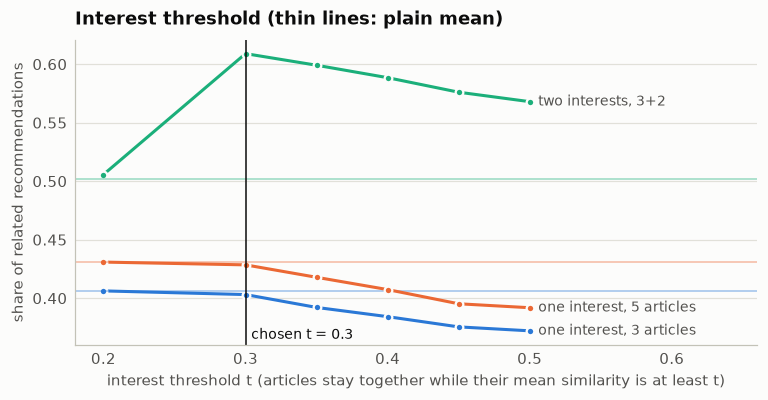

In [29]:
show(evaluation.plot_interest_threshold(recommender_eval), "interest_threshold")

Splitting a history into interests costs almost nothing when it has one topic (−0.003) and gains +0.107
over the mean when it has two; it also serves 93 % of the interests instead of 68 %. A threshold of 0.3
is the best trade-off: lower values merge unrelated interests, higher values split one interest apart.

### 6.3 Limitations

* **Scores are relative.** Because embeddings never drop far below 0.5, unrelated articles still score
  about 0.2. A score is meaningful compared with other scores, not as an absolute probability.
* **The corpus bounds the answers.** Recommendations come only from the 8,800 articles; an article
  fetched on the fly can be visited, but is never recommended.
* **Relevance is approximated.** Subsections and categories are a proxy for what a reader finds
  related; they do not reward surprising but useful recommendations.
* **No diversity re-ranking.** Within one interest, near-duplicates (e.g. *Roman Republic* and *Roman
  Empire*) can both appear.